# 03 XGBoost

Hyperparameters are tuned by randomized search (60 candidates, 5-fold CV) inside each outer fold.
The 2024 notebook instead tried 32,000 configurations on one 25% validation split and reported the
best score on that same split, which is optimistically biased; that is checked at the end.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline

from common import (FIGURES_DIR, INNER_CV, RESULTS_DIR, SEED, load_train, make_preprocessor,
                    nested_cv, save_results, summarize, write_submission)

X, y = load_train()
X.shape

(1504, 32)

In [2]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV, cross_val_score, train_test_split
from xgboost import XGBClassifier


def make_model(**params):
    return Pipeline([("prep", make_preprocessor()),
                     ("clf", XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=1, **params))])


space = {
    "clf__n_estimators": randint(50, 601),
    "clf__max_depth": randint(2, 9),
    "clf__learning_rate": loguniform(0.01, 0.3),
    "clf__subsample": uniform(0.6, 0.4),
    "clf__colsample_bytree": uniform(0.5, 0.5),
    "clf__min_child_weight": randint(1, 11),
}
search = RandomizedSearchCV(make_model(), space, n_iter=60, scoring="accuracy", cv=INNER_CV,
                            random_state=SEED, n_jobs=-1)

## Nested cross-validation

In [3]:
folds, oof, params = nested_cv(search, X, y)
save_results("xgboost", folds, oof, params)
print(params.round(3).to_string(index=False))
summarize(folds)

 fold  clf__colsample_bytree  clf__learning_rate  clf__max_depth  clf__min_child_weight  clf__n_estimators  clf__subsample
    0                  0.542               0.065               2                      4                156           0.871
    1                  0.542               0.065               2                      4                156           0.871
    2                  0.542               0.065               2                      4                156           0.871
    3                  0.542               0.065               2                      4                156           0.871
    4                  0.542               0.065               2                      4                156           0.871


accuracy         precision          recall         specificity  \
                 mean     std      mean     std    mean     std        mean   
rule                                                                          
0.5            0.9574  0.0089    0.9520  0.0196  0.9267  0.0124      0.9743   
recall>=0.90   0.9541  0.0109    0.9569  0.0210  0.9116  0.0160      0.9774   

                         fpr             fnr              f1             auc  \
                 std    mean     std    mean     std    mean     std    mean   
rule                                                                           
0.5           0.0109  0.0257  0.0109  0.0733  0.0124  0.9391  0.0126  0.9576   
recall>=0.90  0.0113  0.0226  0.0113  0.0884  0.0160  0.9336  0.0157  0.9576   

                      
                 std  
rule                  
0.5           0.0101  
recall>=0.90  0.0101

## The 2024 configuration under honest evaluation

2024 final parameters: `n_estimators=36, max_depth=3, learning_rate=0.1, subsample=0.9,
colsample_bytree=0.85`, chosen as the best of 32,000 on the `random_state=0` 25% split.

In [4]:
from common import OUTER_CV

model_2024 = make_model(n_estimators=36, max_depth=3, learning_rate=0.1, subsample=0.9, colsample_bytree=0.85)
X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.25, random_state=0)
split_acc = model_2024.fit(X_tr, y_tr).score(X_va, y_va)
cv_acc = cross_val_score(model_2024, X, y, cv=OUTER_CV, scoring="accuracy")
pd.DataFrame({"evaluation": ["2024 split (the one it was selected on)", "outer 5-fold CV"],
              "accuracy": [split_acc, cv_acc.mean()], "sd": [np.nan, cv_acc.std(ddof=1)]}).to_csv(
    RESULTS_DIR / "xgboost_2024_config.csv", index=False)
print(f"2024 split accuracy: {split_acc:.4f}  (2024 report: 0.9654 with an older xgboost)")
print(f"outer 5-fold CV accuracy: {cv_acc.mean():.4f} +/- {cv_acc.std(ddof=1):.4f}")

2024 split accuracy: 0.9574  (2024 report: 0.9654 with an older xgboost)
outer 5-fold CV accuracy: 0.9521 +/- 0.0060


## Final model and feature importance (gain)

chosen: {'clf__colsample_bytree': np.float64(0.542), 'clf__learning_rate': np.float64(0.065), 'clf__max_depth': 2, 'clf__min_child_weight': 4, 'clf__n_estimators': 156, 'clf__subsample': np.float64(0.871)} | inner CV accuracy 0.9561


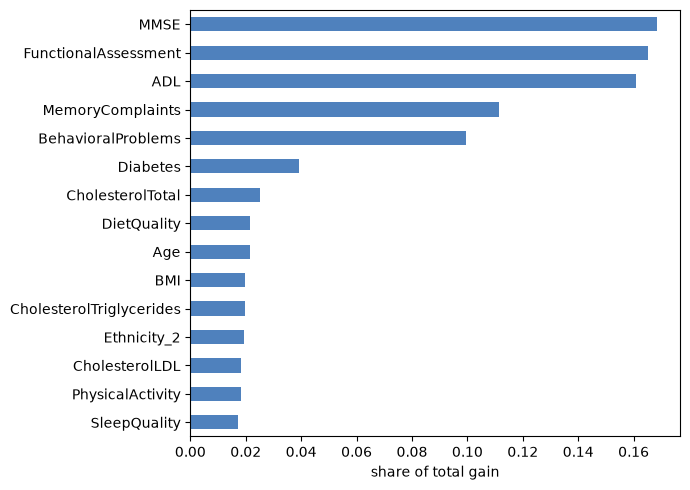

MMSE                    0.168
FunctionalAssessment    0.165
ADL                     0.161
MemoryComplaints        0.111
BehavioralProblems      0.100
Diabetes                0.039
CholesterolTotal        0.025
DietQuality             0.022
dtype: float64

In [5]:
final = search.fit(X, y)
print("chosen:", {k: round(v, 3) if isinstance(v, float) else v for k, v in final.best_params_.items()},
      f"| inner CV accuracy {final.best_score_:.4f}")
booster = final.best_estimator_["clf"].get_booster()
names = final.best_estimator_["prep"].get_feature_names_out()
gain = pd.Series(booster.get_score(importance_type="gain"))
gain.index = [names[int(k[1:])] if k.startswith("f") and k[1:].isdigit() else k for k in gain.index]
gain = (gain / gain.sum()).sort_values(ascending=False)
gain.to_csv(RESULTS_DIR / "xgboost_gain_importance.csv", header=["share_of_gain"])

shown = gain.iloc[:15].iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
shown.plot.barh(ax=ax, color="#4f81bd")
ax.set_xlabel("share of total gain")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "xgb_importance.png", dpi=150)
plt.show()
gain.head(8).round(3)

In [6]:
write_submission("xgboost", final)

PosixPath('submissions/xgboost.csv')